# Chapter 1: Selling a model to people who don't care about AUC: what does the owner hear?

*The model justification: claim, evidence, caveat, action*

**Who needs the answer.** The gym's owner, who pays for the calls and has never heard of AUC. A justification written for the wrong reader gets a polite nod and no budget.

**The questions on the way.** What does the owner need to hear first? How does AUC become members and rupees? What are the four parts, and what number does each carry?

**What you will be able to do.** Turn a model comparison into a four-part justification whose every sentence carries a number the reader can act on.

**Search terms.** presenting ML results to stakeholders, model justification, claim evidence caveat action

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)

# Invented for teaching: 20 lapsed members of a gym in Indore and who came back after a call.
# Model A uses two columns (months since the last visit, visits in the last month); model B uses forty.
import numpy as np, pandas as pd
gym = pd.DataFrame({
    "member":  ["M07", "M12", "M03", "M15", "M01", "M19", "M09", "M05", "M18", "M11",
                "M02", "M14", "M06", "M20", "M08", "M16", "M04", "M13", "M10", "M17"],
    "plan":    ["student", "regular", "regular", "family", "student", "regular", "family", "regular", "student", "family",
                "regular", "regular", "family", "student", "regular", "family", "regular", "student", "regular", "family"],
    "score_A": [0.81, 0.74, 0.66, 0.58, 0.47, 0.41, 0.35, 0.29, 0.24, 0.20,
                0.17, 0.14, 0.11, 0.09, 0.07, 0.05, 0.04, 0.03, 0.02, 0.01],
    "score_B": [0.77, 0.52, 0.70, 0.61, 0.44, 0.40, 0.38, 0.33, 0.21, 0.19,
                0.25, 0.12, 0.10, 0.08, 0.15, 0.03, 0.18, 0.02, 0.04, 0.01],
    "came_back": [1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
})
CALL, MISS = 30, 900   # Rs per comeback call; Rs of margin lost per member who would have returned uncalled
print(f"{len(gym)} members (invented), {gym.came_back.sum()} came back; a call costs Rs {CALL}, a missed comeback Rs {MISS}")

gym

20 members (invented), 5 came back; a call costs Rs 30, a missed comeback Rs 900


,member,plan,score_A,score_B,came_back
0,M07,student,0.81,0.77,1
1,M12,regular,0.74,0.52,1
2,M03,regular,0.66,0.70,0
3,M15,family,0.58,0.61,1
4,M01,student,0.47,0.44,0
5,M19,regular,0.41,0.40,1
6,M09,family,0.35,0.38,0
7,M05,regular,0.29,0.33,0
8,M18,student,0.24,0.21,0
9,M11,family,0.20,0.19,0


## What does the owner need to hear first?

Two models scored the same 20 lapsed members, and the analyst's first draft opens with "Model B has an AUC of 0.85". The owner's question is simpler: whom do I call this week, and what does it save me?

**Predict before you run.** Which opening line gets the calls approved? a) "Model B's AUC is 0.85 against A's 0.80"; b) "Calling A's top 6 brings back 4 of the 5 returners for Rs 180 of calls"; c) "Model A is a logistic regression with five features"; d) "Here is the confusion matrix".

In [2]:
# AUC by hand: every (returner, non-returner) pair, counted when the returner scores higher.
pos, neg = gym[gym.came_back == 1], gym[gym.came_back == 0]
def auc_by_hand(col):
    wins = sum((p > n) for p in pos[col] for n in neg[col])
    return wins, len(pos) * len(neg)
for col in ["score_A", "score_B"]:
    wins, pairs = auc_by_hand(col)
    print(f"{col}: {wins} of {pairs} pairs ranked right, AUC = {wins / pairs:.3f}")

score_A: 60 of 75 pairs ranked right, AUC = 0.800
score_B: 64 of 75 pairs ranked right, AUC = 0.853


In [3]:
from sklearn.metrics import roc_auc_score
check("the hand count agrees with scikit-learn for model A", abs(auc_by_hand("score_A")[0] / 75 - roc_auc_score(gym.came_back, gym.score_A)) < 1e-9)
check("the hand count agrees with scikit-learn for model B", abs(auc_by_hand("score_B")[0] / 75 - roc_auc_score(gym.came_back, gym.score_B)) < 1e-9)

PASS  the hand count agrees with scikit-learn for model A
PASS  the hand count agrees with scikit-learn for model B


**What happened.** The answer is b. AUC is the share of returner and non-returner pairs a model ranks the right way round: 60 of 75 for A, 64 for B. True, and useless to the owner until it is turned into members and rupees, which the next cell does for a week with six calls: both models put the same four returners in their top six.

In [4]:
def plan(col, k):
    top = gym.sort_values(col, ascending=False).head(k)
    found = int(top.came_back.sum()); missed = int(gym.came_back.sum()) - found
    return {"calls": k, "returners found": found, "missed": missed, "call cost Rs": CALL * k, "bill Rs": CALL * (k - found) + MISS * missed}
rows = {"call nobody": plan("score_A", 0), "A, top 6": plan("score_A", 6), "B, top 6": plan("score_B", 6), "call all 20": plan("score_A", 20)}
pd.DataFrame(rows).T

,calls,returners found,missed,call cost Rs,bill Rs
call nobody,0,0,5,0,4500
"A, top 6",6,4,1,180,960
"B, top 6",6,4,1,180,960
call all 20,20,5,0,600,450


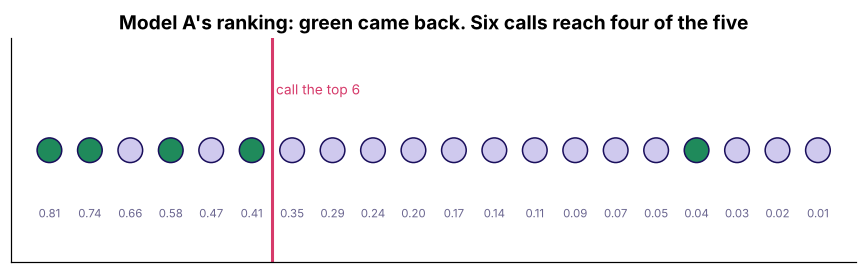

In [5]:
fig, ax = plt.subplots(figsize=(8, 2.6))
g = gym.sort_values("score_A", ascending=False).reset_index(drop=True)
ax.scatter(range(20), [0] * 20, s=260, c=[GREEN if c else LILAC for c in g.came_back], edgecolors=INK)
for i, r in g.iterrows():
    ax.text(i, -0.06, f"{r.score_A:.2f}", ha="center", fontsize=7.5, color=MUTED)
ax.axvline(5.5, color=ROSE, lw=2); ax.text(5.6, 0.05, "call the top 6", color=ROSE, fontsize=9)
ax.set_yticks([]); ax.set_xticks([]); ax.set_ylim(-0.1, 0.1)
ax.set_title("Model A's ranking: green came back. Six calls reach four of the five")
plt.tight_layout(); plt.show()

## What are the four parts, and what number does each carry?

The Week 1 four-part note, at model scale. **Claim**: this model, this cut. **Evidence**: the result against a baseline, in the reader's units. **Caveat**: when it breaks and where it is weakest. **Action**: who does what, how often, and the rule that stops it. The rule with its flip: lead with the decision and the rupees; when the reader is the ML lead reviewing the method, lead with how the evaluation was done.

In [6]:
memo = {
    "claim": "Call model A's top 6 lapsed members this week.",
    "evidence": "Last month 4 of the 5 who came back were in A's top 6, for Rs 180 of calls; calling nobody lost Rs 4,500; B's top 6 found the same 4.",
    "caveat": "20 members is a small sample, so one member moves the hit rate by 17 points; A scored one returner at 0.04.",
    "action": "Reception calls the 6 by Friday; if fewer than 2 of 6 return two weeks running, we stop and rescore.",
}
for part, text in memo.items():
    print(f"{part.upper():9} {text}")
check("every part carries a number", all(any(ch.isdigit() for ch in t) for t in memo.values()))
check("no part leads with AUC", not any(t.lower().startswith("auc") for t in memo.values()))

CLAIM     Call model A's top 6 lapsed members this week.
EVIDENCE  Last month 4 of the 5 who came back were in A's top 6, for Rs 180 of calls; calling nobody lost Rs 4,500; B's top 6 found the same 4.
CAVEAT    20 members is a small sample, so one member moves the hit rate by 17 points; A scored one returner at 0.04.
ACTION    Reception calls the 6 by Friday; if fewer than 2 of 6 return two weeks running, we stop and rescore.
PASS  every part carries a number
PASS  no part leads with AUC


## What did this chapter establish?

| Question | Answer |
|---|---|
| What does the owner hear first? | The decision and its rupees: six calls, four returners, Rs 180 |
| What is AUC in plain words? | The share of returner and non-returner pairs ranked the right way: 60 of 75 for A, 64 for B |
| Why A when B scores higher? | Both find the same four in six calls, and A runs on two columns the desk can check |
| The four parts | Claim, evidence against a baseline, caveat with its condition, action with its rule |

Chapter 2 prices every mistake the cut makes, at every possible cut.